<!-- d2l:prose id=image-diffusion-md-1 fw=all -->

# Diffusion for Images

The velocity regression, probability-flow ODE, and ancestral chain of that section and that section apply in any dimension $d$. Scaling from the plane ($d = 2$) to $28 \times 28$ Fashion-MNIST images ($d = 784$) introduces four practical components:

1. **Architecture:** A multi-resolution U-Net [@Ronneberger.Fischer.Brox.2015; @ho2020denoising] that combines a coarse $7 \times 7$ bottleneck for global image structure with full-resolution skip connections for fine spatial detail, conditioned on time and class embeddings in every residual block.
2. **Training recipe:** Exponential moving averaging (EMA) of the model parameters and random *label dropout* during training so a single network learns both conditional and unconditional velocity fields.
3. **Evaluation:** The Fréchet distance (FD) [@Heusel.Ramsauer.Unterthiner.ea.2017] between real and generated feature distributions extracted by a domain classifier, calibrated against its finite-sample reference floor.
4. **Guidance:** *Classifier-free guidance* (CFG) [@Dhariwal.Nichol.2021; @Ho.Salimans.2022], which extrapolates along the difference between the conditional and unconditional predictions to trade sample diversity for class typicality.

We implement and measure all four components on Fashion-MNIST using a 1.2M-parameter U-Net trainable on a single GPU.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=image-diffusion-md-2 fw=all -->

## The Denoising U-Net

### Skips, Resolutions and the Time Embedding

The network of that section, `TimeMLP`, took a
point and a time and returned a point of the same size. An image network
keeps this contract: a noisy image $\mathbf{x}_t$ and the time $t$ in, a
prediction of the same shape out, here the velocity. Convolutions suit
images, but a stack of $3 \times 3$ convolutions at full resolution makes
each output pixel depend on a small window of the input, while at high noise
the network must decide from the whole image whether a blurred blob is a
shoe or a bag.

The U-Net works at several resolutions. An encoder halves the resolution
twice, from $28 \times 28$ to $14 \times 14$ to $7 \times 7$, and doubles the
channels once, from 64 to 128, so that a $3 \times 3$ convolution at the
bottom sees most of the image; a decoder upsamples back to $28 \times 28$.
The bottleneck alone would lose fine detail, the edge of a sleeve or the
stripes on a sneaker, so the decoder at each resolution also receives the
encoder's features at that resolution, concatenated to its own. These *skip
connections* give the network its U shape (the figure).
Ronneberger et al. designed it to segment structures in microscope images,
a task that asks for one label per pixel: an output of the size of the input
that depends both on the whole image and on the detail at each pixel. A
denoiser asks for the same.

![The U-Net of this section. Two down-sampling stages, a bottleneck at $7 \times 7$, and two up-sampling stages, with skip connections that concatenate encoder features to decoder features at the same resolution. The time and the class label are embedded, passed through a small MLP, and added inside every block.](../img/mdl-diffusion-unet.svg)

One network denoises at every noise level, and the best prediction changes
with the level: near $t = 0$ the clean image is almost the input, at $t = 1$
it can only be guessed as an average over many images. The time therefore
enters every block. `d2l.time_embedding` of that section
maps $t$ to sines and cosines at 64 frequencies, spaced geometrically from 1
to 64 radians per unit of time. This is the construction of the positional
encodings of that section, with frequencies chosen
for times between 0 and 1 instead of positions up to thousands, so that
nearby noise levels get clearly different features. A two-layer MLP turns
them into one vector, and each block adds a learned projection of that
vector to its feature maps, one bias per channel.

Each block applies two $3 \times 3$ convolutions with group normalization,
adds a projection of the conditioning embedding between them, and keeps a
residual connection around both. Group normalization computes its statistics
over groups of channels within one image, so unlike batch normalization it
does not mix the statistics of images at different noise levels.

In [3]:
class UNetBlock(nn.Module):
    """Two 3x3 convolutions with group norm, a residual, and an embedding."""
    def __init__(self, c_in, c_out, emb_dim=None):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.emb = nn.Linear(emb_dim, c_out) if emb_dim else None
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = (nn.Conv2d(c_in, c_out, 1) if c_in != c_out
                     else nn.Identity())

    def forward(self, x, emb=None):
        h = self.conv1(F.silu(self.norm1(x)))
        if self.emb is not None:
            h = h + self.emb(emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

<!-- d2l:prose id=image-diffusion-md-3 fw=all -->

The U-Net goes down to $7 \times 7$ with two stride-2 convolutions and back
up by nearest-neighbor up-sampling to the size of each skip.

In [4]:
class UNet(nn.Module):
    """A small U-Net on an image x (n, c, h, w), times t (n,) and labels y.

    y = num_classes is the null label. cond (n, emb_dim), if given, is added
    to the time features; the flow map of the few-step section passes the
    embedding of its step size there. time_freqs: see time_embedding."""
    def __init__(self, ch=64, num_classes=None, in_channels=1,
                 out_channels=1, emb_dim=128, time_freqs=(1.0, 64.0)):
        super().__init__()
        self.emb_dim, self.num_classes = emb_dim, num_classes
        self.time_freqs = time_freqs
        self.label_emb = (nn.Embedding(num_classes + 1, emb_dim)
                          if num_classes else None)
        self.emb_mlp = d2l.make_mlp([emb_dim] * 3, nn.SiLU())
        self.inc = nn.Conv2d(in_channels, ch, 3, padding=1)
        self.down1 = UNetBlock(ch, ch, emb_dim)                   # 28 x 28
        self.pool1 = nn.Conv2d(ch, ch, 3, stride=2, padding=1)    # 14 x 14
        self.down2 = UNetBlock(ch, 2 * ch, emb_dim)
        self.pool2 = nn.Conv2d(2 * ch, 2 * ch, 3, stride=2, padding=1)  # 7 x 7
        self.mid = UNetBlock(2 * ch, 2 * ch, emb_dim)
        self.up1 = UNetBlock(4 * ch, ch, emb_dim)                 # 14 x 14
        self.up0 = UNetBlock(2 * ch, ch, emb_dim)                 # 28 x 28
        self.outc = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(),
                                  nn.Conv2d(ch, out_channels, 3, padding=1))

    def forward(self, x, t, y=None, cond=None):
        emb = d2l.time_embedding(t, self.emb_dim, self.time_freqs)
        if y is not None:
            emb = emb + self.label_emb(y)
        if cond is not None:
            emb = emb + cond
        emb = self.emb_mlp(emb)
        up = lambda h, skip: torch.cat([F.interpolate(
            h, size=skip.shape[-2:], mode='nearest-exact'), skip], 1)
        h1 = self.down1(self.inc(x), emb)
        h2 = self.down2(self.pool1(h1), emb)
        h = self.mid(self.pool2(h2), emb)
        h = self.up1(up(h, h2), emb)  # skip connection
        h = self.up0(up(h, h1), emb)  # skip connection
        return self.outc(h)

<!-- d2l:prose id=image-diffusion-md-4 fw=all -->

Where does such a network keep its parameters, and where does it compute?
A $3 \times 3$ convolution has the same weights at any resolution but runs
once per pixel, so the same layer costs sixteen times as much at
$28 \times 28$ as at $7 \times 7$. We build the network with 64 channels
at full resolution and ten classes, and count both at each resolution.

In [5]:
torch.manual_seed(0)
dev = d2l.try_gpu()
net = UNet(ch=64, num_classes=10).to(dev)
levels = {28: ['inc', 'down1', 'up0', 'outc'], 14: ['pool1', 'down2', 'up1'],
          7: ['pool2', 'mid']}  # the blocks whose output has each size
for side, names in levels.items():
    params = [p for n in names for p in getattr(net, n).parameters()]
    kernels = sum(p.numel() for p in params if p.dim() == 4)  # convolutions
    print(f'{side} x {side}: {sum(p.numel() for p in params):,} parameters, '
          f'{kernels * side ** 2 / 1e6:.0f}M multiply-adds per image')
print(f'total: {d2l.num_params(net):,} parameters')

28 x 28: 211,329 parameters, 152M multiply-adds per image
14 x 14: 493,376 parameters, 92M multiply-adds per image
7 x 7: 459,776 parameters, 22M multiply-adds per image
total: 1,198,913 parameters


<!-- d2l:prose id=image-diffusion-md-5 fw=all -->

The two lower levels hold four fifths of the parameters and cost two fifths
of the arithmetic; the full-resolution level holds a sixth of the parameters
and costs more than half. At $7 \times 7$ the bottleneck has 38% of the
weights for 8% of the multiply-adds. Depth at low resolution is cheap, which
is why a U-Net puts its widest layers at the bottom. One evaluation of the
network costs about a quarter of a billion multiply-adds, a number to keep
in mind when we count how many evaluations a sample takes.

This is a deliberately bare U-Net. Its 1.2 million parameters are a
thirtieth of the 35.7 million of the CIFAR-10 model of
@ho2020denoising. That model works at four resolutions with two
residual blocks at each and adds self-attention at $16 \times 16$ and
dropout; its released code also sets the last convolution of every block to
zero at initialization, so that each block starts as its skip path. We use
none of these, and the samples below are still recognizable garments. Since
2024, most new large image generators have replaced the U-Net by a
transformer on patches of a compressed image, conditioned on a text prompt
rather than a class (that section); the rest of this
section carries over unchanged.

### Conditioning on a Class

A class label is one more input, and the U-Net already has a place for such
inputs: the embedding that every block adds to its features. A table with
one learned vector per class supplies the label's vector, which is added to
the time features before the MLP. The table has one extra row, the *null
label* $\varnothing$ (index 10 here), which stands for "no class given".

During training we replace each label by the null label with probability
$0.1$, a step called *label dropout*. The one network then learns two
predictions: $\mathbf{u}_{\boldsymbol{\theta}}(\mathbf{x}_t, t, c)$, the
velocity of the images of class $c$, and
$\mathbf{u}_{\boldsymbol{\theta}}(\mathbf{x}_t, t, \varnothing)$, the
velocity of all of Fashion-MNIST, trained on one example in ten. Why teach
a network to ignore the label it is given? Guidance, at the end of this
section (that section), needs the prediction
without a label as a baseline for the one with it, and label dropout
supplies it in the same network at almost no cost.
@Ho.Salimans.2022 found dropout rates of $0.1$ and $0.2$ to work
better than $0.5$: a baseline needs less data than the predictions it
serves.

A sampler integrates a field of $(\mathbf{x}, t)$ alone. `conditional` fixes
the labels $c$ of a batch and turns the network into the field
$(\mathbf{x}, t) \mapsto \mathbf{u}_{\boldsymbol{\theta}}(\mathbf{x}, t, c)$.

In [6]:
def conditional(net, c):
    """The field (x, t) -> net(x, t, c) with the labels c fixed."""
    return lambda x, t: net(x, t, c)

<!-- d2l:prose id=image-diffusion-md-6 fw=all -->

## Training and Sampling

### The Loss and the Cost

The loss is that of that section with images in
place of points. We draw a clean image $\mathbf{x}_0$ in $[-1, 1]$ with its
label, a time $t$ uniform on $[0, 1]$ and noise $\boldsymbol{\epsilon}$,
and form $\mathbf{x}_t = (1 - t)\, \mathbf{x}_0 + t\, \boldsymbol{\epsilon}$
on the linear path. The network's output is regressed onto the conditional
velocity $\boldsymbol{\epsilon} - \mathbf{x}_0$, with the squared error
averaged over the pixels. The only addition is label dropout, which
`batch_fn` applies to each batch of 128 images.

In [7]:
X, y, X_test, y_test = d2l.load_fashion_mnist_pm1()
path = d2l.GaussianPath.linear()

def batch_fn():
    i = torch.randint(0, len(X), (128,), device=X.device)
    drop = torch.rand(128, device=X.device) < 0.1   # label dropout
    return X[i], torch.where(drop, 10, y[i])        # 10 is the null label

def loss_fn(net, batch):
    x0, c = batch
    t, eps = torch.rand(len(x0), device=x0.device), torch.randn_like(x0)
    x_t = path.sample(x0, t, eps)
    return ((net(x_t, t, c) - path.target('velocity', x0, eps, t)) ** 2).mean()

<!-- d2l:prose id=image-diffusion-md-7 fw=all -->

`d2l.train_regression` of that section runs Adam on
this loss and returns the trained network, a moving average of its weights
and the losses. We use a constant learning rate of $10^{-3}$ for 15,000
updates; @ho2020denoising trained with $2 \cdot 10^{-4}$ for 800,000
updates, more than fifty times as many.

Training is the cheaper part of this section. It passes $15{,}000 \times 128
\approx 1.9$ million images forward and backward through the network. The
samples we draw below, some with a thousand steps each, take about 20 million
evaluations: three and a half times the arithmetic of training, counting a
backward pass as two forward ones. Drawing samples from a diffusion model can
cost more than teaching it to draw them, and much of the rest of this chapter
is about cutting that cost. On an RTX 4090 the section runs in less than an
hour; on a CPU it would take many hours. A reader without a GPU can score
1,000 samples instead of 5,000 and read the result against the reference
value at 1,000 images, which we compute below.

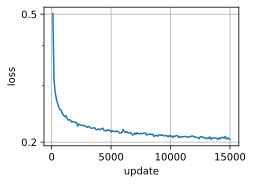

In [8]:
num_steps = 15_000
net, ema, losses = d2l.train_regression(net, loss_fn, batch_fn, num_steps)
d2l.plot(torch.arange(100, num_steps + 1, 100),
         losses.reshape(-1, 100).mean(1).cpu(), 'update', 'loss', yscale='log')

<!-- d2l:prose id=image-diffusion-md-8 fw=all -->

The loss per pixel, averaged over blocks of 100 updates, falls from about
0.5 to about 0.2, most of the way within the first thousand updates. It
levels off well above zero because its floor is the conditional variance of
the velocity target (that section): at large $t$
many clean images are consistent with one noisy image.

### Samples and Predictions

To sample, `d2l.make_pred` of that section turns a
field into a predictor of the clean image and the noise, and
`d2l.ode_sample` integrates the probability-flow ODE from $t = 1$ to $t = 0$,
here with 50 Euler steps. `generate` takes the field as an argument,
`conditional` by default; guidance will pass another. It draws $n$ images,
the $i$-th of class $i \bmod 10$, in chunks. Its initial noise comes from a
seed, 0 unless we say otherwise, so two calls with the same seed differ only
in what we change between them.

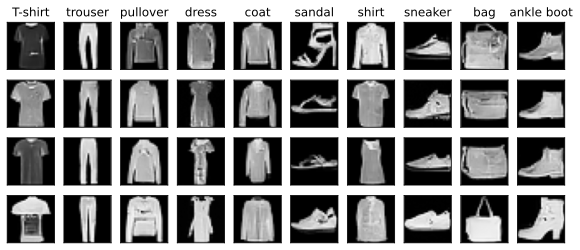

In [9]:
euler50 = lambda pred, x: d2l.ode_sample(pred, x, path.sigma_bars(50))

def generate(model, field=conditional, sampler=euler50, n=5000, chunk=500,
             seed=0):
    """n samples of field(model, c) from the noise of a seed; the i-th
    requests class i % 10."""
    gen = torch.Generator(dev).manual_seed(seed)
    z = torch.randn(n, 1, 28, 28, device=dev, generator=gen)
    c = torch.arange(n, device=z.device) % 10
    out = [sampler(d2l.make_pred(field(model, c_k), path, 'velocity'), z_k)
           for z_k, c_k in zip(z.split(chunk), c.split(chunk))]
    return torch.cat(out).clamp(-1, 1)

names = d2l.FashionMNIST().text_labels(range(10))
d2l.show_gray(generate(ema, n=40), 4, 10, titles=names + [''] * 30);

<!-- d2l:prose id=image-diffusion-md-9 fw=all -->

Each column holds four samples of one class. Most are recognizable members
of the requested class, with varied shapes, prints and shades; some are
malformed, and shirts, pullovers and coats are hard to tell apart, as among
real images.

A sampler asks the network the same question at every level of noise: which
clean image lies behind this one? To see what it can still answer at each
level, the first row below noises one test image, an ankle boot, at six
times on the linear path. The second row shows the clean image
$\hat{\mathbf{x}}_0 = \mathbf{x}_t - t\, \mathbf{u}_{\boldsymbol{\theta}}(\mathbf{x}_t, t, c)$
that the network implies at each of them, given the label. We can predict
both ends of the second row. At $t = 0$ the input is the image. At $t = 1$
it is pure noise, and a network trained with squared error predicts the
posterior mean (that section) given what is left, the
label: the average training image of the class. The first two printed rows
give the root-mean-square distance per pixel of each $\hat{\mathbf{x}}_0$
from the image and from that average.

The third row turns to the sampler itself. It starts from fresh noise and
takes the 50 Euler steps of `euler50` toward an ankle boot, and at
$t = 1, 0.8, \ldots, 0.2$ it records the clean image that the network
implies along the way. The column $t = 0$ holds the finished sample, and the
last printed row gives the distance of each prediction from it.

RMS from the image: 0.00 0.07 0.11 0.16 0.24 0.43
RMS from the class mean: 0.46 0.46 0.45 0.43 0.36 0.07
RMS from the sample: 0.00 0.03 0.07 0.12 0.19 0.32


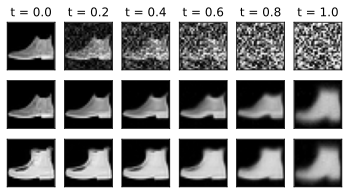

In [10]:
torch.manual_seed(0)
ts = torch.linspace(0, 1, 6, device=dev)
x0, c = X_test[:1].expand(6, -1, -1, -1), y_test[:1].expand(6)
x_t = path.sample(x0, ts, torch.randn_like(x0[:1]).expand_as(x0))
with torch.no_grad():
    x0_hat = path.x0_eps('velocity', ema(x_t, ts, c), x_t, ts)[0]
rms = lambda a, b: ((a - b) ** 2).mean((1, 2, 3)).sqrt().tolist()
for name, ref in (('image', x0), ('class mean', X[y == c[0]].mean(0))):
    print(f'RMS from the {name}:', ' '.join(f'{e:.2f}' for e in rms(x0_hat, ref)))
x, grid, traj = torch.randn_like(x0[:1]), torch.linspace(1, 0, 51), []
with torch.no_grad():  # one sample of the class: 50 Euler steps from noise
    for i in range(50):
        t = grid[i].item()
        u = ema(x, torch.full((1,), t, device=dev), c[:1])
        if i % 10 == 0:                        # t = 1.0, 0.8, ..., 0.2
            traj.append(x - t * u)             # its predicted clean image
        x = x + (grid[i + 1].item() - t) * u
traj = torch.cat([x] + traj[::-1])             # from t = 0 (the sample) to 1
print('RMS from the sample:', ' '.join(f'{e:.2f}' for e in rms(traj, x)))
d2l.show_gray(torch.cat([x_t, x0_hat, traj]), 3, 6,
              titles=[f't = {t:.1f}' for t in ts.tolist()] + [''] * 12);

<!-- d2l:prose id=image-diffusion-md-10 fw=all -->

Both ends come out as predicted: at $t = 1$ the prediction lies within 0.07
of the average ankle boot and more than 0.4 from the image. In between, the
network sees better than our eyes. At $t = 0.6$ the boot is hard to find in
the noise, yet the prediction still has its outline and lies less than 0.2
from this boot against more than 0.4 from the average one. Detail
disappears first and the outline last.

A sampler visits the levels in the opposite order, and the third row shows
what that order does. At $t = 1$ the prediction is the blurred average boot,
0.3 to 0.4 away from the sample it will become. By $t = 0.6$ it lies within
0.12 to 0.14 of that sample and already has its final outline, while the
image it is computed from is still six parts noise to four parts boot. The
remaining steps sharpen the edges and add shading and texture. A sample
settles its shape early and its surface late; Exercise
3 puts this to use.

### The Moving Average

We sampled from `ema`, a moving average of the weights, not from the weights
of the last update. With a constant learning rate the iterates of Adam do
not settle: each update carries the noise of its minibatch, so the iterates
wander in a cloud around a good region, and an average of recent iterates
lies nearer its center [@Polyak.Juditsky.1992]. `d2l.EMA` of
that section keeps an exponential moving average. After every update
it moves the average a small step toward the current weights,

$$\bar{\boldsymbol{\theta}} \leftarrow \bar{\boldsymbol{\theta}} + \big(1 - 2^{-1/n_{1/2}}\big)\, (\boldsymbol{\theta} - \bar{\boldsymbol{\theta}}),$$

so that the weights of $n_{1/2}$ updates ago count half as much as the
current ones; $n_{1/2}$ is the *half-life*. We use $n_{1/2} = 1000$, which
closes 0.07% of the gap at each update. Papers and libraries specify the
*decay* $2^{-1/n_{1/2}}$ instead, here 0.9993, so it helps to translate.

The half-life has to suit the run. Too short, and the average keeps the
noise of the last steps; too long, and it reaches back to early weights
still far from the good region. @ho2020denoising use a decay of
0.9999, a half-life of about 7,000 updates in a run of 800,000. How much the
average helps is the first thing we measure once we have a measure.

## Measuring Sample Quality

### Fréchet Distance in Learned Features

A grid of forty samples shows whether samples look plausible. It cannot tell
whether 5,000 of them have the right variety, whether there are too many
bags and too few sandals, or which of two models that both look fine is
better. For that we need a number that compares the distribution of the
samples with that of real images.

Pixels are the wrong space for such a comparison: shifting a sneaker by two
pixels moves the image far in Euclidean distance without changing what it
shows. We therefore compare images in the feature space of a classifier,
where images of similar content lie close together. The *Fréchet distance*
(FD) of @Heusel.Ramsauer.Unterthiner.ea.2017 fits Gaussians
$\mathcal{N}(\boldsymbol{\mu}_p, \boldsymbol{\Sigma}_p)$ and
$\mathcal{N}(\boldsymbol{\mu}_q, \boldsymbol{\Sigma}_q)$ to the features of
real and generated images and reports the squared Wasserstein-2 distance
between them, given in that section:

$$\mathrm{FD} = \|\boldsymbol{\mu}_p - \boldsymbol{\mu}_q\|^2 + \mathrm{tr}\Big(\boldsymbol{\Sigma}_p + \boldsymbol{\Sigma}_q - 2\big(\boldsymbol{\Sigma}_p^{1/2} \boldsymbol{\Sigma}_q \boldsymbol{\Sigma}_p^{1/2}\big)^{1/2}\Big).$$

The first term grows when the average sample differs from the average real
image, for example when one class is generated too often; the second when
the spread differs, for example when all generated coats look alike. Both
vanish only if the two Gaussians coincide.

Published scores, called FID, use the features of an Inception network
trained on ImageNet. As in that section, we train our own instead:
`d2l.FeatureCNN` (that section), a small convolutional
classifier with 128 features, trained on Fashion-MNIST for 15 epochs with
the gray channel repeated three times. Because the feature network is our
own, we call the score FD and never compare it with published values.
`fashion_feature_cnn` trains it, and `fd_features` computes the features of
images, 1,000 at a time; the network's head assigns each image a class.

In [11]:
def fashion_feature_cnn(X, y):
    """The feature network that judges Fashion-MNIST samples in this chapter."""
    cnn = d2l.FeatureCNN(resolution=28).to(X.device)
    d2l.train_feature_cnn(cnn, X.expand(-1, 3, -1, -1), y)
    return cnn

def fd_features(cnn, imgs):
    """Features of gray images (n, 1, 28, 28) in [-1, 1], on the CPU."""
    rgb = lambda x: x.clamp(-1, 1).expand(-1, 3, -1, -1)
    return d2l.batched(lambda x: cnn.features(rgb(x)), imgs).cpu()

cnn = fashion_feature_cnn(X, y)
f_test = fd_features(cnn, X_test)
c_test = cnn.head(f_test.to(dev)).argmax(1)
print(f'test accuracy {(c_test == y_test).float().mean():.3f}')

test accuracy 0.926


<!-- d2l:prose id=image-diffusion-md-11 fw=all -->

The feature network classifies about 93% of the test images correctly, so
its features separate the classes. `fd_and_agreement` computes the FD of a
set of samples against reference features, together with their *class
agreement*, the fraction of samples that the feature network assigns to the
requested class. We score 5,000 samples against the first 5,000 test
images.

In [12]:
def fd_and_agreement(cnn, imgs, f_ref):
    """FD to the reference features, and the fraction of samples that the
    feature network assigns to the requested class i % 10."""
    f = fd_features(cnn, imgs)
    cls = cnn.head(f.to(imgs.device)).argmax(1)
    agree = (cls == torch.arange(len(imgs), device=cls.device) % 10)
    return d2l.fid_score(f, f_ref), agree.float().mean().item()

fd_ema, agree_ema = fd_and_agreement(cnn, generate(ema), f_test[:5000])
print(f'5,000 samples: FD {fd_ema:.2f}, class agreement {agree_ema:.3f}')

5,000 samples: FD 0.82, class agreement 0.880


<!-- d2l:prose id=image-diffusion-md-12 fw=all -->

The samples score an FD of about 0.8, and the feature network assigns
nearly 90% of them to the class they asked for. Is an FD of 0.8 good? The
number depends on the feature network and on the number of images, and by
itself it says nothing; the next subsection supplies a scale.

### A Reference Value for the Fréchet Distance

Two sets of real images also have a positive FD. Their sample means and
covariances differ by chance, and the plug-in estimate of
the equation is biased upward, mostly in the trace term, by an
amount roughly proportional to $1/n$ for $n$ images per set. To see how
large this is, we score five disjoint sets of real training images against
the first $n$ test images, the reference set of the samples, at
$n = 1{,}000$ and at $n = 5{,}000$. We call the result the *reference value*
of the FD at that size. If the bias goes as $1/n$, the value at 5,000 images
should be about a fifth of that at 1,000. Next to it we print the kernel
inception distance (KID) of @Binkowski.Sutherland.Arbel.ea.2018,
an unbiased estimate of the squared maximum mean discrepancy with a cubic
kernel on the same features (that section), whose expected value for
two sets of real images is zero at every $n$.

In [13]:
f_real = fd_features(cnn, X[:25_000])  # five disjoint sets of 5,000
for n in (1000, 5000):
    sets = [f_real[i * n:(i + 1) * n] for i in range(5)]
    fd = np.array([float(d2l.fid_score(f, f_test[:n])) for f in sets])
    kid = np.array([float(d2l.kid_score(f, f_test[:n])) for f in sets])
    print(f'{n:,} real images, five sets: FD {fd.mean():.2f} '
          f'({fd.min():.2f} to {fd.max():.2f}), KID {kid.mean():.4f} '
          f'({kid.min():.4f} to {kid.max():.4f})')

1,000 real images, five sets: FD 0.88 (0.82 to 0.96), KID 0.0053 (-0.0070 to 0.0227)


5,000 real images, five sets: FD 0.17 (0.15 to 0.19), KID -0.0018 (-0.0051 to 0.0023)


<!-- d2l:prose id=image-diffusion-md-13 fw=all -->

The prediction holds: the reference value is a little under 0.9 at 1,000
images and about 0.17 at 5,000, five times smaller. KID has no such bias,
but it is noisy: at 1,000 images its five values spread over a few
hundredths on both sides of zero, so that one value alone says little, and
at 5,000 over a few thousandths. Papers report the FD, so this chapter does
too, and corrects for its bias by comparison rather than by formula.

The rest of the chapter compares FDs only at the same number of images and
with the same feature network. It treats two FDs of 5,000 images that differ
by less than about 0.05, the spread of the five real sets, as equal; at
1,000 images that spread is 0.15 to 0.2. Later sections print the reference
value beside their scores as the *floor*, the score that a perfect generator
would reach on average.

Our samples, at about 0.8, lie about five times above the reference value
at 5,000 images; the gap is the error of our model. Yet two sets of 1,000
real images score about as much against each other. A Fréchet distance
without its number of images is meaningless.

With a scale in hand we can ask how much the moving average helps, and
whether a thousand-step sampler beats fifty Euler steps. The thousand-step
sampler is the ancestral chain of that section, run
on the variance-preserving path of @ho2020denoising. Our network
was trained on the linear path, but that does not matter: `make_pred` finds
the time on the network's own path with the same signal-to-noise ratio and
rescales, so any trained network serves any path. The comparison is paired:
all three samplers start from the same initial noise, so differences between
noise draws do not enter it, and we repeat it for three draws.

In [14]:
vp = d2l.GaussianPath.vp()
ancestral1000 = lambda pred, x: d2l.ancestral_sample(pred, x, vp, 1000)

<!-- d2l:prose id=image-diffusion-md-14 fw=all -->

Across three shared initial-noise seeds, we now generate 5,000 images from the
EMA weights with `euler50`, the raw final weights `net` with `euler50`, and the
EMA weights with `ancestral1000`, comparing their Fréchet distances against
`f_test[:5000]`:

In [15]:
for seed in range(3):  # three draws of the initial noise
    fd = [fd_and_agreement(cnn, generate(model, sampler=sampler, seed=seed),
                           f_test[:5000])[0]
          for model, sampler in ((ema, euler50), (net, euler50),
                                 (ema, ancestral1000))]
    print(f'noise {seed}: Euler 50 average {fd[0]:.2f}, last weights '
          f'{fd[1]:.2f} ({fd[1] - fd[0]:+.2f}); chain with 1,000 steps '
          f'{fd[2]:.2f} ({fd[2] - fd[0]:+.2f})')

noise 0: Euler 50 average 0.82, last weights 1.36 (+0.55); chain with 1,000 steps 0.69 (-0.13)


noise 1: Euler 50 average 0.84, last weights 1.46 (+0.63); chain with 1,000 steps 0.66 (-0.18)


noise 2: Euler 50 average 0.83, last weights 1.36 (+0.53); chain with 1,000 steps 0.68 (-0.15)


<!-- d2l:prose id=image-diffusion-md-15 fw=all -->

On this network the weights of the last update are worse than their average in
every draw, by 0.4 to 0.6, while the FD of the average moves by only a few
hundredths between draws. How much worse depends on where the last update
happened to land in its cloud, and another training run would land elsewhere.
An average over the last few thousand updates depends much less on such luck,
which is the reason to sample from it. The thousand-step chain scores 0.1 to
0.2 lower than fifty Euler steps, again in every draw. It changes the path,
the sampler and the number of steps at once, so it measures the combination,
not any one of the three. That is a modest gain for twenty times the
evaluations, and from here on we measure with fifty Euler steps.

## Guidance

### Bayes' Rule on Scores

Our conditional samples already belong to their classes nearly 90% of the
time. Some do not: shirts, pullovers and coats were hard to tell apart. The
slider of the introduction asks for more, a sampler that follows the label
more closely than the trained network does. To see where such a sampler could
come from, let us look at what a label does to a score. Bayes' rule at time
$t$ reads $p_t(\mathbf{x} \mid c) = p_t(\mathbf{x})\, p_t(c \mid \mathbf{x})
/ p(c)$, where $p_t(c \mid \mathbf{x})$ is the probability that a noisy image
$\mathbf{x}$ at time $t$ came from a clean image of class $c$, and $p(c)$
drops out of the gradient of the logarithm:

$$\nabla_{\mathbf{x}} \log p_t(\mathbf{x} \mid c) = \nabla_{\mathbf{x}} \log p_t(\mathbf{x}) + \nabla_{\mathbf{x}} \log p_t(c \mid \mathbf{x}).$$

The score of the class is the score of all the data plus the gradient of a
classifier's log-probability. *Classifier guidance*
[@Dhariwal.Nichol.2021] supplies the second term with a separate
classifier $p_{\boldsymbol{\phi}}(c \mid \mathbf{x}, t)$ and multiplies it
by a *guidance scale* $\gamma$:

$$\tilde{\mathbf{s}}(\mathbf{x}, t) = \nabla_{\mathbf{x}} \log p_t(\mathbf{x}) + \gamma\, \nabla_{\mathbf{x}} \log p_{\boldsymbol{\phi}}(c \mid \mathbf{x}, t).$$

With $\gamma = 1$ this is Bayes' rule; @Dhariwal.Nichol.2021 found
that samples matched their classes much better with $\gamma > 1$. The
classifier must be trained on noisy images, since the sampler evaluates its
gradient at $\mathbf{x}_t$, where a classifier of clean images gives
meaningless gradients. The appendix treats the rule on a one-dimensional
mixture (that section); Exercise
2 runs it on our images.

### Classifier-Free Guidance

Classifier guidance needs a second network trained on noisy images, with
its own errors. @Ho.Salimans.2022 read
the equation from right to left instead:

$$\nabla_{\mathbf{x}} \log p_t(c \mid \mathbf{x}) = \nabla_{\mathbf{x}} \log p_t(\mathbf{x} \mid c) - \nabla_{\mathbf{x}} \log p_t(\mathbf{x}).$$

The classifier's gradient is the difference between the conditional and the
unconditional score, and a network trained with label dropout provides both.
Substituting its two scores $\mathbf{s}_c$ and $\mathbf{s}_\varnothing$ into
the equation gives the guided score
$\tilde{\mathbf{s}} = \mathbf{s}_\varnothing + \gamma(\mathbf{s}_c -
\mathbf{s}_\varnothing)$: classifier guidance with the classifier implicit
in the network.

Our network predicts velocities, not scores, but at a fixed point
$(\mathbf{x}, t)$ the velocity is an affine function of the score. On the
linear path the dictionary of that section gives

$$\mathbf{u}_t(\mathbf{x}) = -\frac{\mathbf{x} + t\, \nabla_{\mathbf{x}} \log p_t(\mathbf{x})}{1 - t}.$$

The term $-\mathbf{x}/(1-t)$ does not depend on the label, and the weights
$1 - \gamma$ and $\gamma$ sum to one, so it passes through the combination
unchanged, and the guided velocity is the same combination of the two
velocities:

$$\tilde{\mathbf{u}}(\mathbf{x}, t) = \mathbf{u}_{\boldsymbol{\theta}}(\mathbf{x}, t, \varnothing) + \gamma \big(\mathbf{u}_{\boldsymbol{\theta}}(\mathbf{x}, t, c) - \mathbf{u}_{\boldsymbol{\theta}}(\mathbf{x}, t, \varnothing)\big).$$

`cfg` computes this rule. It evaluates the network on one doubled batch,
the images once with their labels and once with the null label, so a guided
sample costs two evaluations per step. At $\gamma = 1$ the rule reduces to
the conditional field, and `cfg` returns `conditional(net, c)` without the
second half of the batch.

In [16]:
def cfg(net, c, gamma):
    """Classifier-free guidance: (x, t) -> u + gamma (u_c - u), u unlabeled.

    gamma is a Python number; at gamma = 1 this is conditional(net, c)."""
    if gamma == 1:
        return d2l.conditional(net, c)
    null = torch.full_like(c, net.num_classes)
    def guided(x, t):  # one doubled batch: labeled, then unlabeled
        out_c, out = net(torch.cat([x, x]), torch.cat([t, t]),
                         torch.cat([c, null])).chunk(2)
        return out + gamma * (out_c - out)
    return guided

<!-- d2l:prose id=image-diffusion-md-16 fw=all -->

The affine argument holds for every target of the dictionary (Exercise
1). @Ho.Salimans.2022
write the rule as $(1 + w)\, \mathbf{u}_c - w\, \mathbf{u}_\varnothing$, so
their $w$ is our $\gamma - 1$. the figure draws the
rule on the running example: for $\gamma > 1$ the guided prediction lies on
the line through the unconditional and the conditional one, beyond the
conditional one.

![Classifier-free guidance on the three-mode mixture at one noise level. From a noisy point $\mathbf{x}_t$, arrows point to the posterior mean $\hat{\mathbf{x}}_0^{\varnothing}$ of all the data, to the posterior mean $\hat{\mathbf{x}}_0^{c}$ given the top mode, and to the guided prediction $\hat{\mathbf{x}}_0^{\varnothing} + \gamma(\hat{\mathbf{x}}_0^{c} - \hat{\mathbf{x}}_0^{\varnothing})$ at $\gamma = 2$, beyond $\hat{\mathbf{x}}_0^{c}$. Contours show the noised density and the noised density of the top mode.](../img/mdl-diffusion-guidance.svg)

To see what $\gamma$ does to the samples, we generate 5,000 samples at each
of seven scales from the same noise. The FD measures how well they cover the
distribution of real images, the class agreement how well they follow their
labels.

In [17]:
guided = lambda gamma: lambda net, c: cfg(net, c, gamma)
samples = {gamma: generate(ema, guided(gamma))
           for gamma in (0.0, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0)}
for gamma, imgs in samples.items():
    fd, agree = fd_and_agreement(cnn, imgs, f_test[:5000])
    print(f'gamma {gamma:.2f}: FD {fd:5.2f}, class agreement {agree:.3f}')

gamma 0.00: FD  2.74, class agreement 0.099
gamma 1.00: FD  0.82, class agreement 0.880
gamma 1.25: FD  0.84, class agreement 0.931
gamma 1.50: FD  1.13, class agreement 0.962
gamma 2.00: FD  2.05, class agreement 0.985
gamma 3.00: FD  4.07, class agreement 0.997
gamma 4.00: FD  5.86, class agreement 0.999


<!-- d2l:prose id=image-diffusion-md-17 fw=all -->

Without class conditioning ($\gamma = 0$), the class agreement is $10\%$ (chance) and the FD rises to $2.7$–$2.8$, more than three times the conditional FD at $\gamma = 1$ ($\approx 0.8$, with nearly $90\%$ class agreement). To separate how much of the $\gamma = 0$ FD increase comes from skewed class proportions versus degraded image quality within each class, the next cell compares the mean term $\|\boldsymbol{\mu}_p - \boldsymbol{\mu}_q\|^2$ of the equation, inspects the generated class histogram, and computes the FD of 5,000 real training images resampled to match the $\gamma = 0$ class proportions.

In [18]:
for gamma in (0.0, 1.0):
    f = fd_features(cnn, samples[gamma])
    mean_term = ((f.mean(0) - f_test[:5000].mean(0)) ** 2).sum()
    print(f'gamma {gamma:.1f}: mean term {mean_term:.2f} of FD '
          f'{d2l.fid_score(f, f_test[:5000]):.2f}')
share = lambda cls: torch.bincount(cls, minlength=10) / len(cls)
cls = cnn.head(fd_features(cnn, samples[0.0]).to(dev)).argmax(1)
for name, s_test, s_0 in zip(names, share(c_test), share(cls)):
    print(f'{name:>11}: test images {s_test:.3f}, gamma 0 {s_0:.3f}')
# real training images, 5,000 in the class mix of the gamma = 0 samples
counts, y_real = torch.bincount(cls, minlength=10).tolist(), y[:25_000].cpu()
mixed = torch.cat([torch.nonzero(y_real == k)[:n, 0]
                   for k, n in enumerate(counts)])
for name, f in (('uniform', f_real[:5000]), ('gamma 0', f_real[mixed])):
    mean_term = ((f.mean(0) - f_test[:5000].mean(0)) ** 2).sum()
    print(f'real images, {name} class mix: mean term {mean_term:.2f} of FD '
          f'{d2l.fid_score(f, f_test[:5000]):.2f}')

gamma 0.0: mean term 0.71 of FD 2.74
gamma 1.0: mean term 0.28 of FD 0.82
    T-shirt: test images 0.101, gamma 0 0.097
    trouser: test images 0.099, gamma 0 0.080
   pullover: test images 0.102, gamma 0 0.144
      dress: test images 0.102, gamma 0 0.097
       coat: test images 0.099, gamma 0 0.100
     sandal: test images 0.099, gamma 0 0.074
      shirt: test images 0.096, gamma 0 0.104
    sneaker: test images 0.103, gamma 0 0.095
        bag: test images 0.100, gamma 0 0.099
 ankle boot: test images 0.098, gamma 0 0.111


real images, uniform class mix: mean term 0.04 of FD 0.19
real images, gamma 0 class mix: mean term 0.13 of FD 0.38


<!-- d2l:prose id=image-diffusion-md-18 fw=all -->

Although the unconditional sampler overproduces pullovers ($13\%$–$14\%$) and underproduces sandals ($6\%$–$7\%$), imposing this same class skew on real images raises the FD by only $0.2$–$0.3$ (from $0.19$ to $0.4$–$0.5$), accounting for less than a sixth of the $1.9$ FD gap between $\gamma = 1$ and $\gamma = 0$. The remaining gap arises because the unconditional field $\mathbf{u}_{\boldsymbol\theta}(\mathbf{x}_t, t, \varnothing)$, trained on only $10\%$ of the minibatches across all ten classes simultaneously, produces more malformed or ambiguous garments. Because the equation can be written as $\mathbf{u}_c + (\gamma - 1)(\mathbf{u}_c - \mathbf{u}_\varnothing)$, any error in the unconditional baseline $\mathbf{u}_\varnothing$ enters guided samples with weight $1 - \gamma$.

Increasing $\gamma$ beyond $1$ illustrates the diversity–typicality trade-off. Mild guidance ($\gamma = 1.25$) raises class agreement by about five percentage points (to $93\%$–$94\%$) without increasing the FD beyond run-to-run noise. For $\gamma \ge 1.5$, class agreement climbs past $96\%$ (exceeding $99\%$ at $\gamma = 3$ and $4$, higher than the classifier's accuracy on real test images), while the FD rises steadily to $5.5$–$6$ as within-class diversity collapses onto high-contrast canonical prototypes:

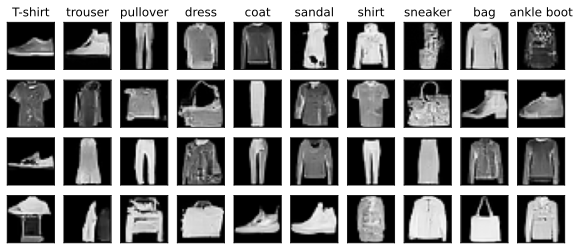

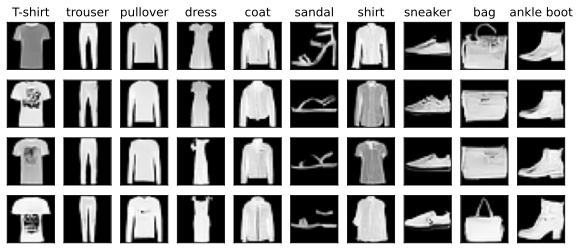

In [19]:
for gamma in (0.0, 4.0):
    d2l.show_gray(generate(ema, guided(gamma), n=40), 4, 10,
                  titles=names + [''] * 30)

<!-- d2l:prose id=image-diffusion-md-19 fw=all -->

In practice, text-to-image systems use strong guidance scales because a human user evaluates individual images for prompt adherence and visual clarity rather than evaluating the covariance of a 5,000-sample batch.

### The Distribution a Guided Sampler Follows

At $\gamma = 1$ the sampler draws from the class and at $\gamma = 0$ from
all images; at any other scale the rule of the equation was
never derived from a distribution. Let us look for one anyway. The guided
score $\nabla \log p_t(\mathbf{x}) + \gamma\, \nabla \log p_t(c \mid \mathbf{x})$
is the gradient of the logarithm of the *tilted* density

$$\tilde{p}_t(\mathbf{x}) \propto p_t(\mathbf{x})\, p_t(c \mid \mathbf{x})^{\gamma} \propto p_t(\mathbf{x})^{1 - \gamma}\, p_t(\mathbf{x} \mid c)^{\gamma}.$$

For $\gamma > 1$ the classifier's probability is raised to a power, which
shifts mass toward the images about which the classifier is most certain;
equivalently, part of the unconditional density is divided out, which pushes
samples away from regions that the class shares with the others.

How large is this effect? The smallest case answers it in closed form. Let
the images of class $c$ be distributed as
$\mathcal{N}(\boldsymbol{\mu}_c, s^2\mathbf{I})$, and caricature all images
together by one broader Gaussian $\mathcal{N}(\mathbf{0}, S^2\mathbf{I})$,
$S^2 > s^2$. This is the boldest assumption of the section, since a mixture
of ten classes is no Gaussian; it is also the one that makes every answer
exact. The logarithm of a Gaussian is a quadratic, so the tilt of the
clean images, $\gamma \log p(\mathbf{x} \mid c) + (1 - \gamma) \log
p(\mathbf{x})$ up to a constant, is again the logarithm of a Gaussian.
Collecting its quadratic and linear terms gives the inverse variance $1/v$
and the mean,

$$\frac{1}{v} = \frac{\gamma}{s^2} - \frac{\gamma - 1}{S^2}, \qquad \textrm{mean} = \frac{\gamma v}{s^2}\, \boldsymbol{\mu}_c.$$

The class's inverse variance is counted $\gamma$ times and that of all images
subtracted $\gamma - 1$ times. For $\gamma > 1$ the result exceeds $1/s^2$ by
$(\gamma - 1)(1/s^2 - 1/S^2) > 0$, and the factor in front of
$\boldsymbol{\mu}_c$ exceeds one: guidance narrows the class and pushes it
away from the mean of all images. In one dimension, with $\mu_c = 1$,
$s = 0.5$ and $S^2 = 2$, the scale $\gamma = 4$ shrinks the standard
deviation of the class from 0.5 to 0.26 and moves its mean from 1 to 1.10.
This is the trade of variety for typicality, in a formula.

Does the guided sampler at least end at this narrower Gaussian? No, and the
difference is large. In one dimension the guided velocity of this example
is affine in $x$ at every $t$, so the probability-flow ODE carries a
Gaussian to a Gaussian, and its mean and variance can be integrated exactly.
It turns out that the sampler overshoots the tilt itself: started from pure
noise at $\gamma = 4$, it ends with mean 1.23 and standard deviation 0.02,
a class shrunk more than twentyfold, to less than a tenth of the width of
the tilted Gaussian.

The tilt at $t = 0$ is not the distribution the sampler follows, because the
tilted densities at $t > 0$ are not the noised versions of it, nor of any
other clean distribution. A density obtained by adding Gaussian noise of
variance $\sigma_t^2$ cannot curve more sharply than the noise itself: no
eigenvalue of $-\nabla^2 \log p_t$ exceeds $1/\sigma_t^2$
(that section has the proof). On the linear
path $\sigma_t = t$, and the two Gaussians stay Gaussian, with variances
$(1 - t)^2 s^2 + t^2$ and $(1 - t)^2 S^2 + t^2$. The same calculation as at
$t = 0$ shows that the tilt breaks the bound near $t = 1$ whenever
$\gamma > S^2/(S^2 - s^2)$, which is $8/7$ in our example. At
$\gamma = 1.5$ it does so for every $t$ above 0.47, and at $\gamma = 4$ for
every $t$ above 0.24 (Exercise 6).
Over much of its path the guided sampler follows fields that pull harder
than any noised distribution can, and their pull compounds from step to
step. The appendix finds the same for two classes in one dimension
(that section).

Since the trouble lies at high noise,
@Kynkaanniemi.Aittala.Karras.ea.2024 switch guidance off there and
guide only in a middle range of noise levels, which keeps most of the gain
in agreement at a smaller loss of variety; Exercise
3 tries it on our model.
@Karras.Aittala.Kynkaanniemi.ea.2024 change the base instead:
they replace the unconditional prediction by a smaller or less trained
version of the conditional model, whose errors resemble those of the model
being guided, so that extrapolating away from it removes errors rather than
variety.

All of this is expensive. Each guided sample above cost a hundred network
evaluations, fifty steps of a doubled batch, and the thousand-step chain did
only a little better than fifty steps. How few evaluations are enough is
the question of that section.

## Summary

A denoising U-Net pairs low-resolution bottleneck layers, which capture global context with most of the parameters and a fraction of the arithmetic, with full-resolution skip connections that preserve sharp spatial edges, injecting time and class embeddings into every residual block. Sampling from an exponential moving average (EMA) of the weights substantially reduces the Fréchet distance compared with using the final Adam iterate, while the Fréchet distance itself carries a positive $O(1/n)$ finite-sample bias and must always be read against the reference floor between disjoint real sets of the same size $n$. Finally, random label dropout trains conditional and unconditional fields inside a single network so that classifier-free guidance $\tilde{\mathbf{u}} = \mathbf{u}_\varnothing + \gamma(\mathbf{u}_c - \mathbf{u}_\varnothing)$ can steer generation: mild scales ($\gamma \approx 1.25$) raise class agreement without hurting FD, whereas larger scales ($\gamma > 1.5$) trade sample diversity for typicality because high-noise tilted scores contract variance more sharply than any Gaussian-convolved density.

## Exercises

1. **Equivalent guidance rules.** Suppose that the network's two velocities
   are exact, so that, by the dictionary of
   that section, they are affine functions of the
   scores $\nabla \log p_t(\mathbf{x} \mid c)$ and
   $\nabla \log p_t(\mathbf{x})$, and that the classifier is the exact class
   posterior $p_t(c \mid \mathbf{x})$ of the noisy images.
    1. Show that classifier guidance
       the equation at scale $\gamma$ and
       classifier-free guidance the equation at the same
       $\gamma$ produce the same guided velocity.
    1. Every target of the dictionary (the noise, the clean image, the score,
       $\mathbf{v}$ and the velocity) is, at a fixed $(\mathbf{x}, t)$, an
       affine function $a(\mathbf{x}, t) + b(t)\, \hat{\mathbf{x}}_0$ of the
       posterior mean $\hat{\mathbf{x}}_0$. Show that applying the rule to
       any one target and converting gives the same guided prediction as
       applying it to any other. Which property of the weights $1 - \gamma$
       and $\gamma$ does the argument use?
    1. Would the rule still be the same for every target if a network
       predicted $\hat{\mathbf{x}}_0$ clipped to $[-1, 1]$?
1. [code] **A clean classifier as guide.** ● Classifier guidance needs a
   classifier of noisy images, but one can also steer with a classifier of
   clean images applied to the network's estimate of the clean image.
    1. Report the accuracy of the feature network `cnn` on test images noised
       to $\mathbf{x}_t$ at $t \in \{0.25, 0.5, 0.75\}$ of the linear path.
       How do these accuracies explain why the text asks for a classifier
       trained on noisy images?
    1. Use the posterior mean $\hat{\mathbf{x}}_0(\mathbf{x}_t)$ of the
       unconditional prediction (`cfg(ema, c, 0.0)`) as the classifier's
       input instead, and add
       $\gamma\, \nabla_{\mathbf{x}_t} \log p_{\textrm{cnn}}(c \mid \hat{\mathbf{x}}_0(\mathbf{x}_t))$
       to the unconditional score, converted to a velocity with the
       dictionary. Sample 1,000 images at $\gamma \in \{1, 3, 10\}$ with
       50 Euler steps.
    1. Score the samples with `fd_and_agreement`. The class agreement is
       now measured by the same network that steered the sampler. Train a
       second `d2l.FeatureCNN` with another seed and score the samples with
       it as well. What does the comparison say about using a classifier
       both to guide and to evaluate?
1. [code] **Guidance in a limited interval.**
   @Kynkaanniemi.Aittala.Karras.ea.2024 apply guidance only within
   an interval of noise levels and use $\gamma = 1$ elsewhere. They measure
   the noise level by $\bar\sigma_t = \sigma_t / \alpha_t$ and found
   $0.28 < \bar\sigma_t \leq 2.9$ best for one of their ImageNet models.
    1. Find the times $t$ of the linear path at which $\bar\sigma_t$ equals
       $0.28$ and $2.9$.
    1. Write a version of `cfg` that applies the scale $\gamma$ only for
       $t$ in a given interval. At $\gamma = 4$, compute the FD and the class
       agreement of 5,000 samples for guidance in the high-noise interval,
       the middle interval and the low-noise interval, and compare with
       guidance at every step and with $\gamma = 1$.
    1. Which interval accounts for most of the gain in agreement, and which
       for most of the rise in FD? Relate the answer to the time at which a
       sample commits to its class, Exercise
       4 of
       that section, and to the third row of the
       strip of predictions in this section. Exercise
       5 of
       that section asks the same question
       for two classes in one dimension.
1. [code] **Skip connections.** Write a variant of `UNet` without its two
   skip connections, in which `up1` and `up0` receive only the upsampled
   features, so that their input widths shrink to `2 * ch` and `ch`.
    1. Before training, predict at which times $t$ the skip connections
       matter most and at which they hardly matter.
    1. Train both networks for 5,000 updates. For 1,000 test images,
       compute the squared error of the clean image implied by each
       network's velocity, $\hat{\mathbf{x}}_0 = \mathbf{x}_t - t\, \hat{\mathbf{u}}$,
       at $t \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$, and plot both curves.
    1. Compare the FD of 5,000 samples of each network. Does the error
       curve of (b) predict the difference?
1. [code] **Thresholding the predicted image.** ● The guided velocity implies a
   clean image $\hat{\mathbf{x}}_0 = \mathbf{x}_t - t\, \tilde{\mathbf{u}}$
   on the linear path. @saharia2022photorealistic trace the
   saturated samples of large guidance scales to predictions
   $\hat{\mathbf{x}}_0$ outside the range of the data.
    1. For $\gamma \in \{1, 4, 16\}$, record at every Euler step the fraction
       of pixels of $\hat{\mathbf{x}}_0$ outside $[-1, 1]$ and plot it
       against $t$. Where along the path does the prediction leave the
       range, and how does $\gamma$ change this?
    1. *Static thresholding* clips $\hat{\mathbf{x}}_0$ to $[-1, 1]$ before
       the step; *dynamic thresholding* sets, for each image, $m$ to the
       larger of $1$ and the 99.5th percentile of $|\hat{\mathbf{x}}_0|$,
       clips to $[-m, m]$ and divides by $m$. Rewrite the Euler step to form
       the velocity from a thresholded $\hat{\mathbf{x}}_0$, and implement
       both.
    1. Define the *saturation* of a set of images as the fraction of its
       pixels equal to $1$ after clamping. Compare saturation, FD and class
       agreement of the three samplers at $\gamma \in \{4, 8, 16\}$.
1. **Guidance on Gaussian classes.** ● Take the Gaussian classes of this
   section: class $c$ distributed as
   $\mathcal{N}(\boldsymbol{\mu}_c, s^2 \mathbf{I})$ and all images as
   $\mathcal{N}(\mathbf{0}, S^2 \mathbf{I})$ with $S^2 > s^2$, noised on the
   linear path.
    1. Derive the inverse variance and the mean of the tilted Gaussian at
       $t = 0$ given in the text. Then show that at every $t$ the guided
       score $\gamma \nabla \log p_t(\mathbf{x} \mid c) + (1 - \gamma) \nabla \log p_t(\mathbf{x})$
       is the score of a Gaussian, find its variance, and show that it falls
       below $t^2$ near $t = 1$ exactly when $\gamma > S^2/(S^2 - s^2)$.
    1. In one dimension, with $\mu_c = 1$, $s^2 = 0.25$ and $S^2 = 2$, the
       guided velocity is affine in $x$ at every $t$. Write down the ODEs
       for the mean and the variance, integrate them from
       $\mathcal{N}(0, 1)$ at $t = 0.999$ to $t = 0$ for
       $\gamma \in \{1, 2, 4\}$, and check the text's endpoint at
       $\gamma = 4$ (mean 1.23, standard deviation 0.02). Compare each
       endpoint with the tilted Gaussian at $t = 0$, and explain the
       difference with the bound of the text.
    1. The truncation trick of Exercise
       5 of
       that section, applied to the
       generator $\boldsymbol{\mu}_c + s \mathbf{z}$, and sampling from
       $p(\mathbf{x} \mid c)^{1/T}$ at a temperature $T < 1$ also narrow the
       class. Which of the three methods moves the class mean as well, and
       why?

[Discussions](https://d2l.discourse.group/t/36822)